# A2.2 Stochastic simulation of predator–prey dynamics

State: $(\hat x(t), \hat y(t))$, the numbers of prey and predators. Events and rates:

| Event | Rate $w_k(x,y)$ | $(\Delta x, \Delta y)$ |
|---|---|---|
| 1. prey birth | $\alpha x$ | $(+1, 0)$ |
| 2. prey death | $\sigma x$ | $(-1, 0)$ |
| 3. predation, no predator born | $\lambda xy$ | $(-1, 0)$ |
| 4. predation, predator born | $\delta xy$ | $(-1, +1)$ |
| 5. predator death | $\gamma y$ | $(0, -1)$ |

Parameters from Eq. (4): $\alpha=4$, $\sigma=1$, $\lambda=\delta=10^{-3}$, $\gamma=1$, $x(0)=500$, $y(0)=1000$, $T=16$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

params = {'alpha': 4.0, 'sigma': 1.0, 'lam': 1e-3, 'delta': 1e-3, 'gamma': 1.0}
x0 = (500, 1000)
T = 16.0

## a. Gillespie's method for the predator–prey model

We implement a generic Gillespie function: it takes a list of rate functions and a list of state variations, so it works for any model. From state $\mathbf{x}$ at time $t$, it computes the rates $w_k(\mathbf{x})$ and the total rate $W(\mathbf{x})=\sum_k w_k(\mathbf{x})$, draws the waiting time from an exponential distribution with mean $1/W$, and picks event $k$ with probability $w_k/W$ using `rng.choice`. It stops when the next event would fall after $T$, or when $W=0$ (absorbing state, e.g. both species extinct).

Only the rate functions and the state variations are specific to the predator–prey model.

In [2]:
def gillespie(x0, T, rng, rate_functions, state_changes, params):
    # Return the event times {t_k} and the state right after each event {x_k}
    x = np.array(x0, dtype=int)
    t = 0.0
    times, states = [t], [x.copy()]
    deltas = np.array(state_changes, dtype=int)
    n_events = len(rate_functions)
    while True:
        rates = np.array([w(x, params) for w in rate_functions], dtype=float)
        W = rates.sum()
        if W <= 0.0:  # absorbing state: no event can happen
            break
        t += rng.exponential(1.0 / W)
        if t > T:
            break
        k = rng.choice(n_events, p=rates / W)
        x = x + deltas[k]
        times.append(t)
        states.append(x.copy())
    return np.array(times), np.array(states)


# Rate functions of the predator-prey model, state s = (x, y)
def prey_birth(s, p):
    return p['alpha'] * s[0]

def prey_death(s, p):
    return p['sigma'] * s[0]

def predation_no_birth(s, p):
    return p['lam'] * s[0] * s[1]

def predation_with_birth(s, p):
    return p['delta'] * s[0] * s[1]

def predator_death(s, p):
    return p['gamma'] * s[1]

pp_rates = [prey_birth, prey_death, predation_no_birth, predation_with_birth, predator_death]
pp_changes = [(+1, 0), (-1, 0), (-1, 0), (-1, +1), (0, -1)]

### Deterministic limit

The Lotka–Volterra equations (3) are integrated with RK4 from Assignment 1, with $M=16000$ steps ($h=10^{-3}$).

In [3]:
def rk4(rhs, y0, T, M):
    h = T / M
    t = np.linspace(0.0, T, M + 1)
    y = np.empty((M + 1, len(y0)))
    y[0] = y0
    for k in range(M):
        yk = y[k]
        k1 = rhs(yk)
        k2 = rhs(yk + 0.5 * h * k1)
        k3 = rhs(yk + 0.5 * h * k2)
        k4 = rhs(yk + h * k3)
        y[k + 1] = yk + h * (k1 + 2*k2 + 2*k3 + k4) / 6.0
    return t, y

def lotka_volterra(z, p=params):
    x, y = z
    return np.array([(p['alpha'] - p['sigma']) * x - (p['lam'] + p['delta']) * x * y,
                     p['delta'] * x * y - p['gamma'] * y])

t_det, z_det = rk4(lotka_volterra, np.array(x0, dtype=float), T, 16_000)

Quick check of the implementation: we simulate one trajectory up to $t=1$ and compare the observed frequency of each event type with its expected frequency. The rates change as the state moves, so the expected frequency is the average of $w_k(\mathbf{x})/W(\mathbf{x})$ over the states just before each event.

In [4]:
rng = np.random.default_rng(4124)
t_test, s_test = gillespie(x0, 1.0, rng, pp_rates, pp_changes, params)
print(f'{len(t_test) - 1} events up to t = 1')

# Probability of each event in the state just before it happens: w_k / W
w = np.array([[rate(s, params) for rate in pp_rates] for s in s_test[:-1]])
p = w / w.sum(axis=1, keepdims=True)

# Events 2 and 3 have the same state variation (-1, 0), so they are counted together
labels = ['prey birth (+1,0)', 'prey death or predation (-1,0)',
          'predation with birth (-1,+1)', 'predator death (0,-1)']
expected = np.array([p[:, 0], p[:, 1] + p[:, 2], p[:, 3], p[:, 4]]).mean(axis=1)
d = np.diff(s_test, axis=0)
observed = np.array([np.all(d == v, axis=1).mean() for v in [(1, 0), (-1, 0), (-1, 1), (0, -1)]])
for label, e, o in zip(labels, expected, observed):
    print(f'{label:32s} expected {e:.3f}   observed {o:.3f}')

7385 events up to t = 1
prey birth (+1,0)                expected 0.506   observed 0.515
prey death or predation (-1,0)   expected 0.247   observed 0.244
predation with birth (-1,+1)     expected 0.120   observed 0.123
predator death (0,-1)            expected 0.127   observed 0.119


Events 2 and 3 have the same state variation, so they cannot be told apart in the trajectory and are counted together. The observed frequencies match the expected ones to within about $0.01$, which is the size of the sampling noise for about $7400$ events (standard error $\sqrt{p(1-p)/n} \approx 0.004$–$0.006$).

## b. Spaghetti plots

We generate 50 trajectories up to $T=16$ (this takes about two minutes). The trajectories are kept in `trajectories` so they can be reused in parts c and d.

In [5]:
n_traj = 50
rng = np.random.default_rng(2026)
trajectories = [gillespie(x0, T, rng, pp_rates, pp_changes, params) for _ in range(n_traj)]

n_events = [len(t) - 1 for t, _ in trajectories]
print(f'events per trajectory: mean = {np.mean(n_events):.0f}, min = {min(n_events)}, max = {max(n_events)}')
print('trajectories with an extinction before T:',
      sum(np.any(s[-1] == 0) for _, s in trajectories))

events per trajectory: mean = 150383, min = 147192, max = 155579
trajectories with an extinction before T: 0


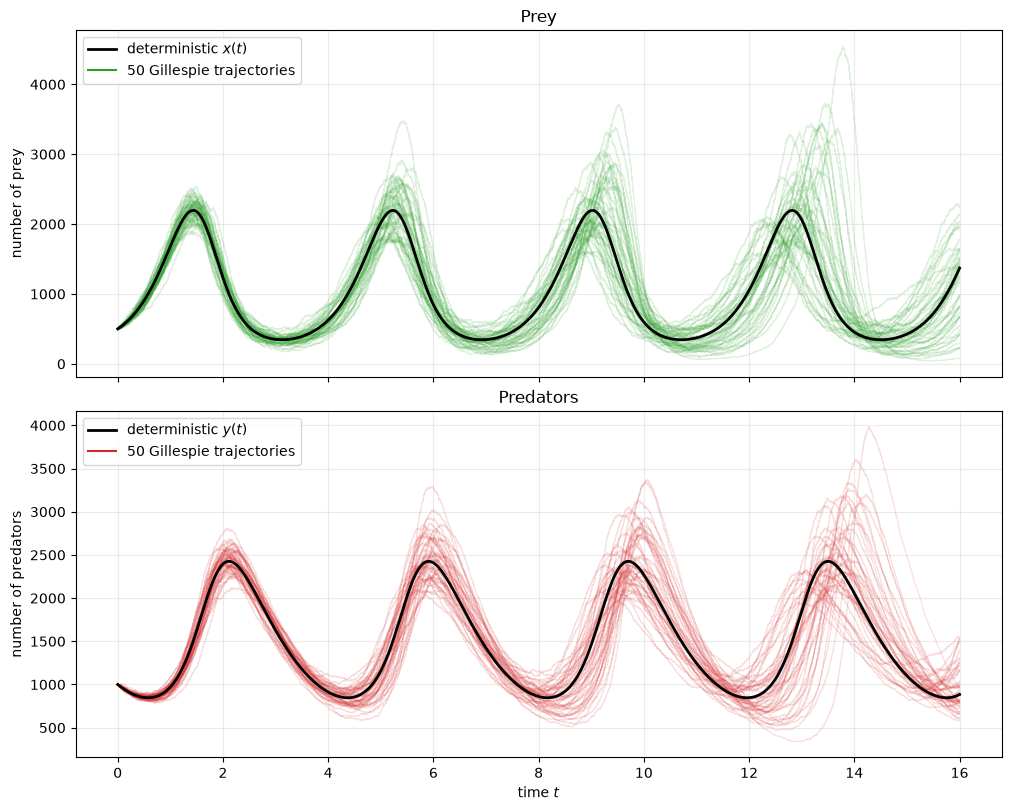

In [6]:
fig, (ax_x, ax_y) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, constrained_layout=True)

for t, s in trajectories:
    ax_x.step(t, s[:, 0], where='post', color='tab:green', alpha=0.15, linewidth=0.8)
    ax_y.step(t, s[:, 1], where='post', color='tab:red', alpha=0.15, linewidth=0.8)

ax_x.plot(t_det, z_det[:, 0], 'k', linewidth=2, label='deterministic $x(t)$')
ax_y.plot(t_det, z_det[:, 1], 'k', linewidth=2, label='deterministic $y(t)$')

# Proxy artists for the legend of the stochastic trajectories
ax_x.plot([], [], color='tab:green', label=f'{n_traj} Gillespie trajectories')
ax_y.plot([], [], color='tab:red', label=f'{n_traj} Gillespie trajectories')

ax_x.set(ylabel='number of prey', title='Prey')
ax_y.set(xlabel='time $t$', ylabel='number of predators', title='Predators')
for ax in (ax_x, ax_y):
    ax.grid(alpha=0.25)
    ax.legend(loc='upper left')
plt.show()

### Comments

- **Early times ($t \lesssim 2$).** All 50 stochastic trajectories stay in a narrow band around the deterministic curves. With hundreds to thousands of individuals, the random fluctuations are small compared with the population sizes, so the deterministic model describes the first oscillation well.
- **Same qualitative behaviour.** Every stochastic trajectory oscillates like the deterministic one: prey peaks come first and predator peaks follow, with a period close to the deterministic one (about $3.8$ time units). No trajectory went extinct before $T=16$.
- **The spread grows with time.** From one cycle to the next, the stochastic trajectories spread out more and more, both in **amplitude** (some prey peaks exceed $3500$, others stay under $2000$) and in **phase** (the peaks no longer happen at the same time). By $t\approx 13$–$16$, the spread between trajectories is comparable to the size of the deterministic oscillation itself (at the fourth prey peak, $t\approx 13$, the trajectories range from about $1000$ to over $3000$ prey), and many trajectories are clearly out of phase with the deterministic curve.
- **Why.** The deterministic Lotka–Volterra model has a family of closed orbits (a conserved quantity) and no attracting cycle, so nothing pulls a perturbed trajectory back to the deterministic orbit. Each random event moves the stochastic trajectory to a slightly different orbit, and these displacements accumulate like a random walk. Orbits with larger amplitude also have a longer period, so a trajectory that was pushed to a larger orbit falls behind in phase; this is visible in the trajectories with the highest peaks, which arrive later than the deterministic peak.

The deterministic model is therefore a good description of a single realization only over the first cycle or so. Over longer horizons, it gives the shape and the period of the oscillations but not the value of $\hat x(t)$ and $\hat y(t)$ at a given time.

### AI Use Declaration

**1. Did you use a generative AI tool while completing this assignment?** Yes.

**2. How did you use generative AI?**
- writing or revising code;
- debugging code or interpreting error messages;
- interpreting data, results, tables, or plots;
- writing or revising explanations.

**3. Sections or tasks where AI was used, and how it influenced our work.**
We used AI to review and fix problems. The AI review confirmed our Gillespie function, rate functions and state variations, and AI rewrote our check of the event frequencies so that it compares each event type with its expected frequency over the states actually visited, rather than only at the initial state.

**4. How did we verify the AI-generated suggestions, code, or explanations?**
We checked the Gillespie function step by step against the direct method seen in class (exponential waiting time with mean $1/W$, event $k$ chosen with probability $w_k/W$), and checked each rate and state variation against the table of events in the assignment. We compared the observed frequency of each event type over a trajectory up to $t=1$ with its expected frequency (the average of $w_k/W$ over the visited states), and checked that the stochastic trajectories follow the deterministic solution during the first cycle. We checked each statement in the comments against the plots and the printed outputs (period of about $3.8$, no extinction before $T=16$, spread of the peaks, peaks of the larger trajectories arriving later than the deterministic peaks).

**5. Confirmation.**
*I confirm that this declaration is complete and that I understand and can explain everything in my submission.*